In [1]:
import numpy as np 
import pandas as pd 

import matplotlib.pyplot as plt 

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [4]:
titanic = pd.read_csv("titanic_toy.csv")
titanic.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [5]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       714 non-null    float64
 1   Fare      846 non-null    float64
 2   Family    891 non-null    int64  
 3   Survived  891 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 28.0 KB


In [8]:
titanic.isnull().sum()

Age         177
Fare         45
Family        0
Survived      0
dtype: int64

In [10]:
titanic.isnull().mean()*100

Age         19.865320
Fare         5.050505
Family       0.000000
Survived     0.000000
dtype: float64

In [13]:
x = titanic.iloc[:, :3]
y = titanic.iloc[:, 3]

In [14]:
x_train, x_test, y_train, y_test = train_test_split(
    x, 
    y, 
    test_size= 0.2, 
    random_state= 2
)

x_train.shape, x_test.shape

((712, 3), (179, 3))

# 1. Handling Missing numerical values using pandas

In [15]:
x_train.isnull().mean()

Age       0.207865
Fare      0.050562
Family    0.000000
dtype: float64

In [16]:
x_test.isnull().mean()

Age       0.162011
Fare      0.050279
Family    0.000000
dtype: float64

In [19]:
train_mean_age = x_train["Age"].mean()
train_median_age = x_train["Age"].median()

train_mean_fare = x_train["Fare"].mean()
train_median_fare = x_train["Fare"].median()

In [22]:
x_train["mean_age"] = x_train["Age"].fillna(train_mean_age)
x_train["median_age"] = x_train["Age"].fillna(train_median_age)

x_train["mean_fare"] = x_train["Fare"].fillna(train_mean_fare)
x_train["median_fare"] = x_train["Fare"].fillna(train_median_fare)

In [23]:
x_train.shape

(712, 7)

In [27]:
x_train.sample(5)

,Age,Fare,Family,mean_age,median_age,mean_fare,median_fare
435,14.0,120.0000,3,14.000000,14.00,120.0000,120.0000
413,NaN,0.0000,0,29.785904,28.75,0.0000,0.0000
48,NaN,21.6792,2,29.785904,28.75,21.6792,21.6792
727,NaN,7.7375,0,29.785904,28.75,7.7375,7.7375
506,33.0,26.0000,2,33.000000,33.00,26.0000,26.0000


In [28]:
print("Variance of Age:", x_train["Age"].var())
print("Variance of mean_Age:", x_train["mean_age"].var())
print("Variance of median_Age:", x_train["median_age"].var())


print("Variance of Fare:", x_train["Fare"].var())
print("Variance of mean_Fare:", x_train["mean_fare"].var())
print("Variance of median_Fare:", x_train["median_fare"].var())

Variance of Age: 204.3495133904614
Variance of mean_Age: 161.81262452718673
Variance of median_Age: 161.9895663346054
Variance of Fare: 2448.197913706318
Variance of mean_Fare: 2324.2385256705547
Variance of median_Fare: 2340.0910219753637


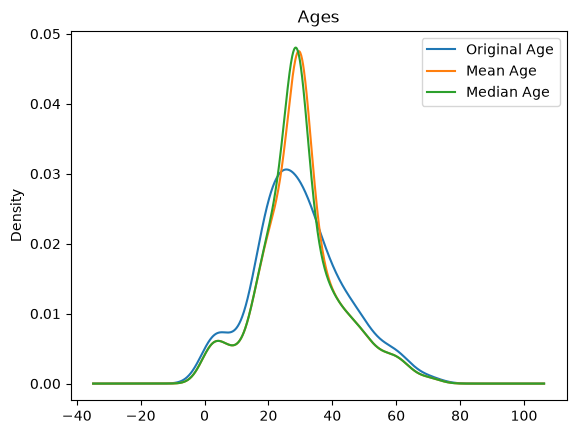

In [32]:

figure = plt.figure()
ax = figure.add_subplot(111)

x_train["Age"].plot(ax= ax, kind= "kde", label= "Original Age")
x_train["mean_age"].plot(ax= ax, kind= "kde", label= "Mean Age")
x_train["median_age"].plot(ax= ax, kind= "kde", label= "Median Age")

plt.legend()
plt.title("Ages")
plt.show()

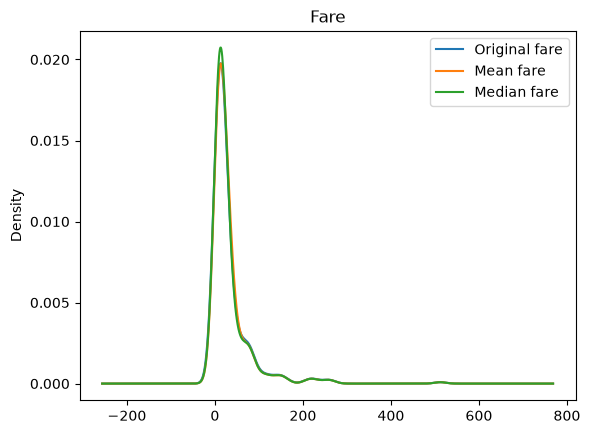

In [34]:

figure = plt.figure()
ax = figure.add_subplot(111)

x_train["Fare"].plot(ax= ax, kind= "kde", label= "Original fare")
x_train["mean_fare"].plot(ax= ax, kind= "kde", label= "Mean fare")
x_train["median_fare"].plot(ax= ax, kind= "kde", label= "Median fare")

plt.legend()
plt.title("Fare")
plt.show()

In [35]:
# Fare Distribution is nearly equivalent to the original fare. So this is okay. 
# But the age distribution has a drastic change in the graph Which is Red flag. 

In [36]:
x_train.cov()

,Age,Fare,Family,mean_age,median_age,mean_fare,median_fare
Age,204.349513,70.719262,-6.498901,204.349513,204.349513,66.665205,64.858859
Fare,70.719262,2448.197914,17.258917,55.603719,57.957599,2448.197914,2448.197914
Family,-6.498901,17.258917,2.735252,-5.146106,-5.112563,16.385048,16.476305
mean_age,204.349513,55.603719,-5.146106,161.812625,161.812625,52.788341,51.358000
median_age,204.349513,57.957599,-5.112563,161.812625,161.989566,55.023037,53.553455
mean_fare,66.665205,2448.197914,16.385048,52.788341,55.023037,2324.238526,2324.238526
median_fare,64.858859,2448.197914,16.476305,51.358000,53.553455,2324.238526,2340.091022


<Axes: >

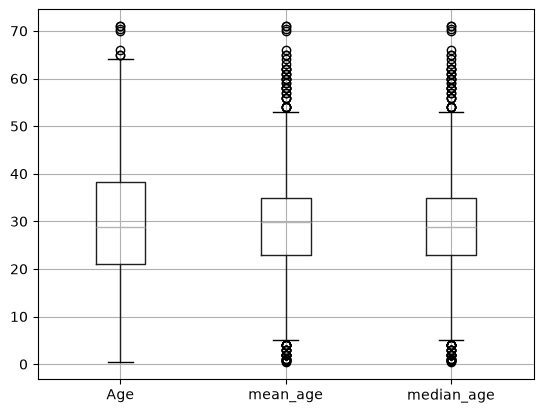

In [37]:
x_train[["Age", "mean_age", "median_age"]].boxplot()

<Axes: >

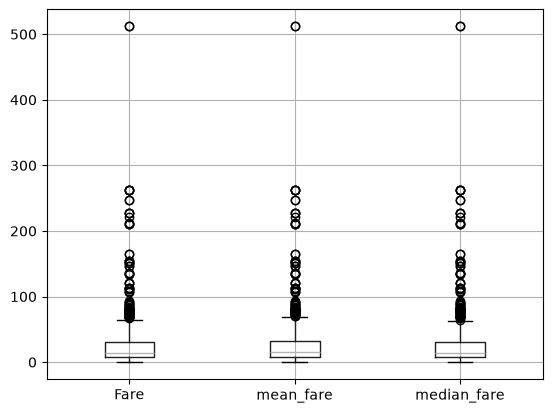

In [38]:
x_train[["Fare", "mean_fare", "median_fare"]].boxplot()

# 2. Handling missing values using SKLEARN

## Mean/Median Imputation

In [41]:
X_train, X_test, Y_train, Y_test = train_test_split(
    x, 
    y, 
    test_size= 0.2, 
    random_state= 2
)

X_train.shape, X_test.shape

((712, 3), (179, 3))

In [42]:
imputer1 = SimpleImputer(strategy="mean")
imputer2 = SimpleImputer(strategy= "median")

In [43]:
trf = ColumnTransformer([
    ("imputer1", imputer1, ["Age"]), 
    ("imputer2", imputer2, ["Fare"])
], remainder= "passthrough")

In [51]:
trf.fit(X_train)

,transformers,"[('imputer1', ...), ('imputer2', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'mean'
,fill_value,None


In [52]:
trf.named_transformers_["imputer1"].statistics_

array([29.78590426])

In [53]:
trf.named_transformers_["imputer2"].statistics_

array([14.4583])

In [54]:
X_train_transformed = trf.transform(X_train)
X_test_transformed = trf.transform(X_test)

In [55]:
X_train_transformed

array([[ 40.        ,  27.7208    ,   0.        ],
       [  4.        ,  16.7       ,   2.        ],
       [ 47.        ,   9.        ,   0.        ],
       ...,
       [ 71.        ,  49.5042    ,   0.        ],
       [ 29.78590426, 221.7792    ,   0.        ],
       [ 29.78590426,  25.925     ,   0.        ]], shape=(712, 3))

## Arbitrary Value Imputation

In [56]:
X_train.columns

Index(['Age', 'Fare', 'Family'], dtype='object')

In [57]:
X_train["Age_99"] = X_train["Age"].fillna(99)
X_train["Age_-1"] = X_train["Age"].fillna(-1)


X_train["Fare_99"] = X_train["Fare"].fillna(99)
X_train["Fare_-1"] = X_train["Fare"].fillna(-1)

In [59]:
print("Age variance: ", X_train["Age"].var())
print("Age_99 variance: ", X_train["Age_99"].var())
print("Age_-1 variance: ", X_train["Age_-1"].var())


print("Fare variance: ", X_train["Fare"].var())
print("Fare_99 variance: ", X_train["Fare_99"].var())
print("Fare_-1 variance: ", X_train["Fare_-1"].var())

Age variance:  204.3495133904614
Age_99 variance:  951.7275570187172
Age_-1 variance:  318.0896202624484
Fare variance:  2448.197913706318
Fare_99 variance:  2536.0773428319685
Fare_-1 variance:  2378.5676784883503


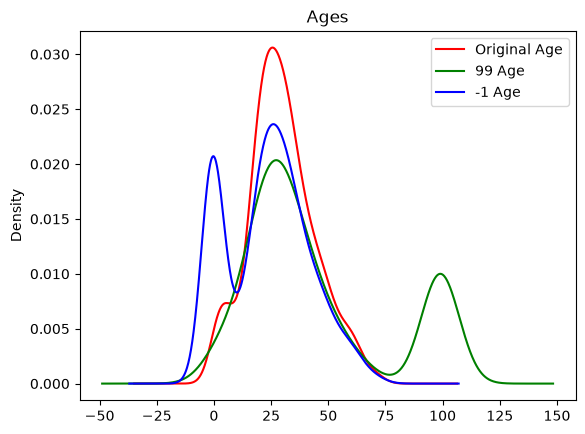

In [63]:
figure_2 = plt.figure()
ax_1 = figure_2.add_subplot(111)

X_train["Age"].plot(kind= "kde", color= "REd", label= "Original Age", ax= ax_1)
X_train["Age_99"].plot(kind= "kde", color= "Green", label= "99 Age", ax= ax_1)
X_train["Age_-1"].plot(kind= "kde", color= "Blue", label= "-1 Age", ax= ax_1)

plt.legend()
plt.title("Ages")
plt.show()

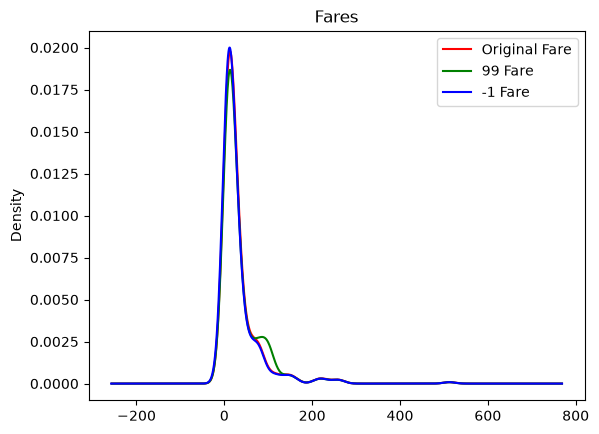

In [64]:
figure_2 = plt.figure()
ax_1 = figure_2.add_subplot(111)

X_train["Fare"].plot(kind= "kde", color= "REd", label= "Original Fare", ax= ax_1)
X_train["Fare_99"].plot(kind= "kde", color= "Green", label= "99 Fare", ax= ax_1)
X_train["Fare_-1"].plot(kind= "kde", color= "Blue", label= "-1 Fare", ax= ax_1)

plt.legend()
plt.title("Fares")
plt.show()

In [65]:
train_x, test_x, train_y, test_y = train_test_split(
    x,
    y,
    test_size= 0.2, 
    random_state= 2
)

In [67]:
train_x.shape, test_x.shape

((712, 3), (179, 3))

In [68]:
imputer3 = SimpleImputer(strategy= "constant", fill_value= 99)
imputer4 = SimpleImputer(strategy= "constant", fill_value= -1)

In [69]:
trf2 = ColumnTransformer([
    ("imputer3", imputer3, ["Age"]), 
    ("imputer4", imputer4, ["Fare"])
], remainder= "passthrough")

In [73]:
trf2.fit(train_x)

,transformers,"[('imputer3', ...), ('imputer4', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'constant'
,fill_value,99


In [74]:
trf2.named_transformers_["imputer3"].statistics_


array([99.])

In [75]:
trf2.named_transformers_["imputer4"].statistics_

array([-1.])

In [76]:
train_x_transform= trf2.transform(train_x)
test_x_transform= trf2.transform(test_x)